In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate
import sympy

In [3]:
sympy.init_printing()

In [4]:
c1 = 1
c2 = 7
c3 = 8
A = (c1 % 5) + 2
B = (c2 % 4) + 1
C = (c3 % 5) + 1

In [ ]:
f"{A=}, {B=}, {C=}"

'A=3, B=4, C=4'

# D1

## 1

In [ ]:
t = sympy.symbols("t")
y = sympy.Function("y")

In [7]:
L_expr = y(t).diff(t) + A * y(t)
R_expr = B * sympy.sin(t)
expr = sympy.Eq(L_expr, R_expr)

## 2

In [8]:
solution = sympy.dsolve(expr, y(t), ics={y(0): C})

In [9]:
solution

## 3

In [10]:
check = sympy.checkodesol(expr, solution)

In [11]:
check[0]

True

## 4

In [ ]:
y0 = sympy.symbols("y0")
solution = sympy.dsolve(expr, y(t), ics={y(0): y0})

In [13]:
t_vals = np.linspace(0, 10, 200)

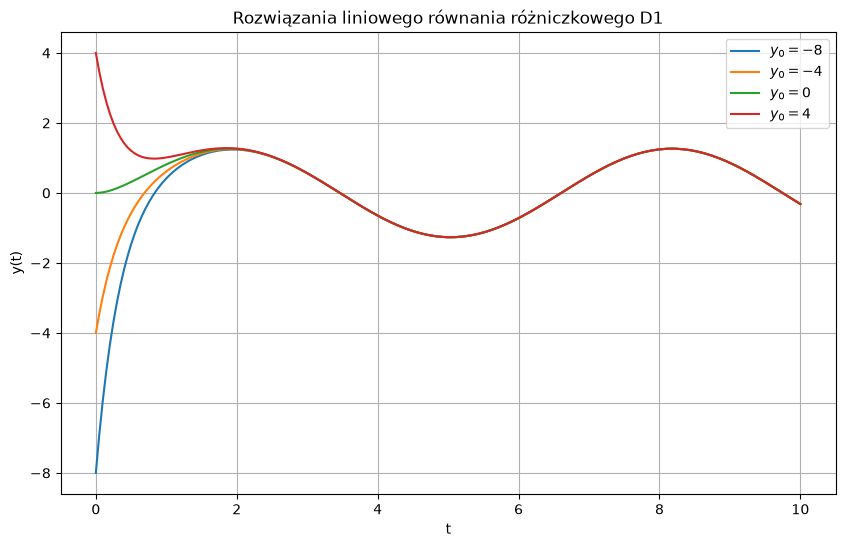

In [15]:
plt.figure(figsize=(10, 6))

for y0_val in [-2 * C, -C, 0, C]:
    solution_expression = solution.rhs.subs(y0, y0_val)
    y_func = sympy.lambdify(t, solution_expression, "numpy")

    plt.plot(t_vals, y_func(t_vals), label=f"$y_0 = {y0_val}$")

plt.xlabel("t")
plt.ylabel("y(t)")
plt.title("Rozwiązania liniowego równania różniczkowego D1")
plt.legend()
plt.grid(True)
plt.show()

# D2

In [ ]:
x = sympy.symbols("x")
y = sympy.Function("y")
ode = sympy.Eq(y(x).diff(x), (1 / A) * y(x) ** 2 - x / B)

## 1

In [17]:
f1 = (1 / A) * y(x) ** 2 - x / B
f_np = sympy.lambdify((x, y(x)), f1, "numpy")
x_np = np.linspace(-4, 4, 20)
y_np = np.linspace(-4, 4, 20)
X, Y = np.meshgrid(x_np, y_np)
U1 = np.ones((20, 20))
V1 = f_np(X, Y)

# normalizacja
U1n = U1 / np.sqrt(U1**2 + V1**2)
V1n = V1 / np.sqrt(U1**2 + V1**2)

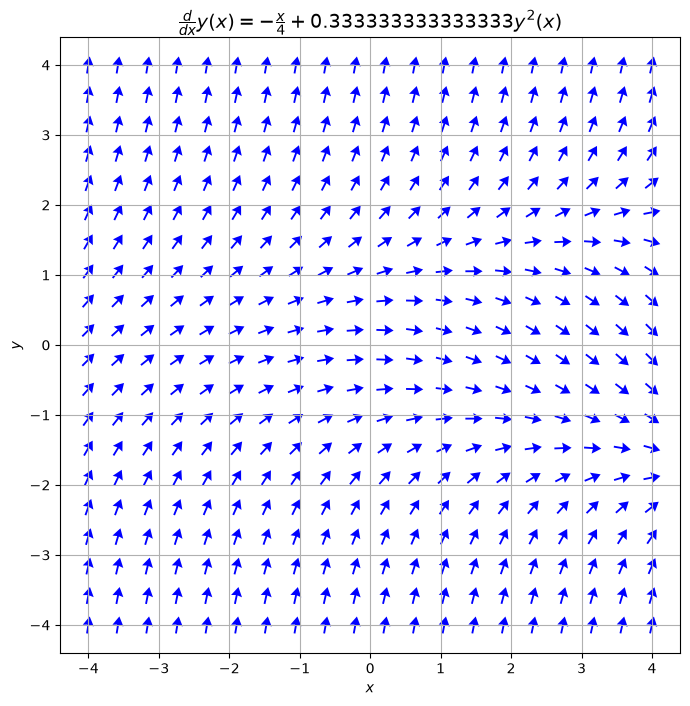

In [ ]:
plt.figure(figsize=(8, 8))
plt.quiver(X, Y, U1n, V1n, pivot="mid", headwidth=6, color="blue")
plt.title(r"$%s$" % sympy.latex(sympy.Eq(y(x).diff(x), f1)), fontsize=14)
plt.xlabel("$x$", fontsize=10)
plt.ylabel("$y$", fontsize=10)
plt.grid(True)
plt.show()

## 2

In [26]:
ode_series = sympy.dsolve(ode, y(x), ics={y(0): C / 5}, hint="1st_power_series", n=6)
ode_series

## 3

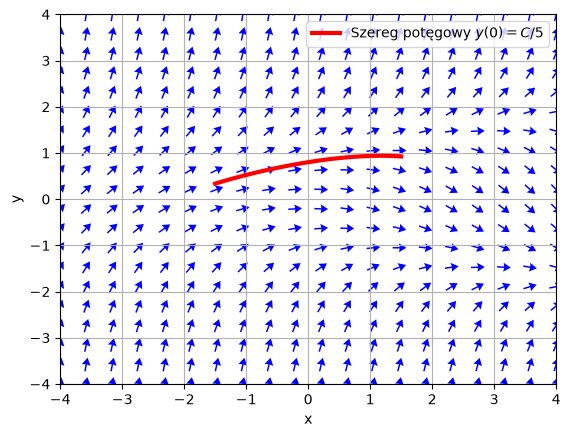

In [33]:
ode_polynomial = ode_series.rhs.removeO()
y_polynomial_function = sympy.lambdify(x, ode_polynomial, "numpy")

x_plot = np.linspace(-1.5, 1.5, 100)
y_plot = y_polynomial_function(x_plot)

plt.plot(x_plot, y_plot, color="red", linewidth=3, label="Szereg potęgowy $y(0)=C/5$")
plt.quiver(X, Y, U1n, V1n, pivot="mid", headwidth=6, color="blue")
plt.xlim([-4, 4])
plt.ylim([-4, 4])
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()